# Análisis exploratorio de datos

Apartado del enunciado: 3.1

## Carga de datos

In [ ]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [7]:
pd.set_option('display.max_columns', None) # Por si se quiere ver todas las columnas del DataFrame
pd.set_option('display.max_rows', None) # Por si se quiere ver todas las filas del DataFrame
pd.set_option('display.max_colwidth', None) # Por si se quiere ver todo el contenido de las columnas del DataFrame

In [8]:
# Configuración de estilo visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Ruta robusta al dataset (ejecutando desde la carpeta /notebooks)
DATA_PATH = Path("../data/raw/enfermedad_cardiovascular.csv")

if not DATA_PATH.exists():
    # Alternativa si se ejecuta desde la raíz del proyecto
    DATA_PATH = Path("data/raw/enfermedad_cardiovascular.csv")

df = pd.read_csv(DATA_PATH)

print(
    f"✓ Dataset cargado correctamente con {df.shape[0]} filas y {df.shape[1]} columnas."
)
assert df.shape == (
    2254,
    28,
), f"Dimensiones inesperadas: {df.shape} (se esperaban 2254 filas y 28 columnas)"

df.head()

✓ Dataset cargado correctamente con 2254 filas y 28 columnas.


,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,6.5,7.6,9.4,3.80,3.70,69.5,3.3,110.4,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,5.0,8.7,0.0,4.07,4.67,87.5,5.6,88.4,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,8.7,9.7,20.8,3.39,7.15,100.6,1.2,123.8,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2
3,54.9,112.8,97.9,179.20,53.9,137.9,174.4,92.0,28.6,47.4,5.7,5.6,10.0,0.75,4.81,92.0,1.5,93.3,4.06,0,1,0,0,1,Occidental,Ligeramente activo,Paterno,0
4,47.2,115.1,97.0,242.20,56.5,159.2,195.7,63.5,18.5,69.0,6.7,-4.9,5.5,NaN,10.13,93.7,5.7,91.0,4.63,0,0,0,0,0,Occidental,Muy activo,Ninguno,0


En una primera instancia llama la atención las columnas `edad` y `anos_fumador` por presentar el valor con decimales a pesar de especificar que venían expresados en años. Si no hay errores o atípicos en estas dos columnas, habría que determinar si dejarlos con decimales puede perjudicar o no a los resultados. Hay otros datos que aunque en teoría deberían de ser discretos, tienen decimales, como `consumo_alcohol_semanal`, lo que indica que seguramente los datos se calcularon haciendo la media semanal. En principio, la idea sería no redondearlo para no perder innecesariamente información precisa. Las columnas `colesterol_hdl` y `colesterol_ldl` podrían estar relacionadas con la columna `colesterol_total`, habría que investigar si hay alguna fórmula que los relacione y seguramente ver su correlación. A simple vista se puede ver que la base de datos presenta valores nulos. También hay presencia de variables categóricas, por lo que si en el futuro se van a emplear modelos que no admiten nominales, habrá que aplicarles una codificación (ya sea implícita porque haya un orden claro, como parece ser el caso de `nivel_actividad`, o añadida manualmente). Tampoco parecen haber variables con datos que no sirvan para medir riesgo cardiovascular, por lo que a priori no se debería descartar ninguna columna.

## Descripción general

In [9]:
print("=" * 60)
print("1. INFORMACIÓN DE TIPOS Y ESTRUCTURA")
print("=" * 60)
df.info()

print("\n" + "=" * 60)
print("2. REGISTROS DUPLICADOS")
print("=" * 60)
duplicados = df.duplicated().sum()
print(f"Total de filas duplicadas exactas: {duplicados}")

print("\n" + "=" * 60)
print("3. ANÁLISIS DE VALORES FALTANTES (MISSING VALUES)")
print("=" * 60)
nulos = df.isnull().sum()
pct_nulos = (df.isnull().sum() / len(df)) * 100
df_nulos = pd.DataFrame(
    {"Nulos": nulos, "Porcentaje (%)": pct_nulos.round(2)}
).query("Nulos > 0")

if len(df_nulos) > 0:
    print(df_nulos.sort_values(by="Porcentaje (%)", ascending=False))
else:
    print("No se han detectado valores nulos explícitos (NaN).")

# Clasificación de columnas según su naturaleza para su posterior tratamiento
TARGET_COL = "riesgo_cardiovascular"
BOOL_COLS = [
    "fumador_actual",
    "hipertension_previa",
    "diabetes_mellitus",
    "tratamiento_estatinas",
    "uso_antihipertensivos",
]
CAT_COLS = [
    "tipo_alimentacion",
    "nivel_actividad",
    "antecedentes_familiares_tipo",
]
NUM_COLS = [
    c
    for c in df.columns
    if c not in BOOL_COLS + CAT_COLS + [TARGET_COL] and pd.api.types.is_numeric_dtype(df[c])
]

print(
    f"\nVariables clasificadas: {len(NUM_COLS)} numéricas, {len(BOOL_COLS)} booleanas, {len(CAT_COLS)} categóricas y 1 target."
)

# Resumen estadístico numérico
print("\n" + "=" * 60)
print("4. ESTADÍSTICOS DESCRIPTIVOS BÁSICOS (NUMÉRICAS)")
print("=" * 60)
df[NUM_COLS].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]

1. INFORMACIÓN DE TIPOS Y ESTRUCTURA
<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 n

,mean,std,min,25%,50%,75%,max
edad,56.688287,14.448018,9.80,47.20,56.90,66.475,103.50
presion_sistolica,132.315186,26.931005,52.20,115.30,129.65,143.900,231.36
presion_diastolica,82.167524,13.084058,30.80,73.60,82.10,91.100,122.50
colesterol_total,228.133829,62.725948,61.10,188.20,221.20,252.500,448.59
colesterol_hdl,47.225200,15.991614,-8.80,36.70,47.30,58.200,106.30
colesterol_ldl,135.638603,36.732756,6.10,111.40,135.50,161.400,266.70
trigliceridos,176.657391,72.735893,-35.70,133.05,170.00,208.100,452.70
glucosa_ayunas,104.107330,24.939696,32.00,86.30,103.75,120.475,194.00
indice_masa_corporal,28.093390,6.470585,3.60,23.80,28.00,32.500,50.60
frecuencia_cardiaca_reposo,73.668190,12.762546,25.80,65.00,73.10,82.300,112.70


Como se intuía, la base de datos tiene valores nulos, estando en las variables `horas_sueno_diarias`, `proteina_c_reactiva`, `colesterol_ldl`, `glucona_ayunas`. En cuanto a los tipos de datos, se confirman las 3 variables categóricas, a las que seguramente se les deberá hacer una codificación. Los 5 booleanos están correctamente representados con un entero. En cuanto a las variables numéricas, todas están representadas con float. La base de datos no presenta ejemplos duplicados.

En cuanto al resumen estadístico de las variables numéricas, hay varios resultados a comentar:
* La `edad` mínima es de 9.80, lo que significa que hay menores de edad en los ejemplos. Como la predicción es para la población adulta, estos ejemplos seguramente sean eliminados.
* Hay varios atributos que no deberían de poder tener valores negativos. Estos son `colesterol_hdl`, `trigliceridos` y `consumo_alcohol_semanal`.
* La variable `frecuencia_ejercicio_semanal` tiene un valor máximo de 10, cuando esta se mide en días de la semana, por lo que aunque se esté haciendo la media el valor no debería poder ser más de 7.

## Análisis univariante

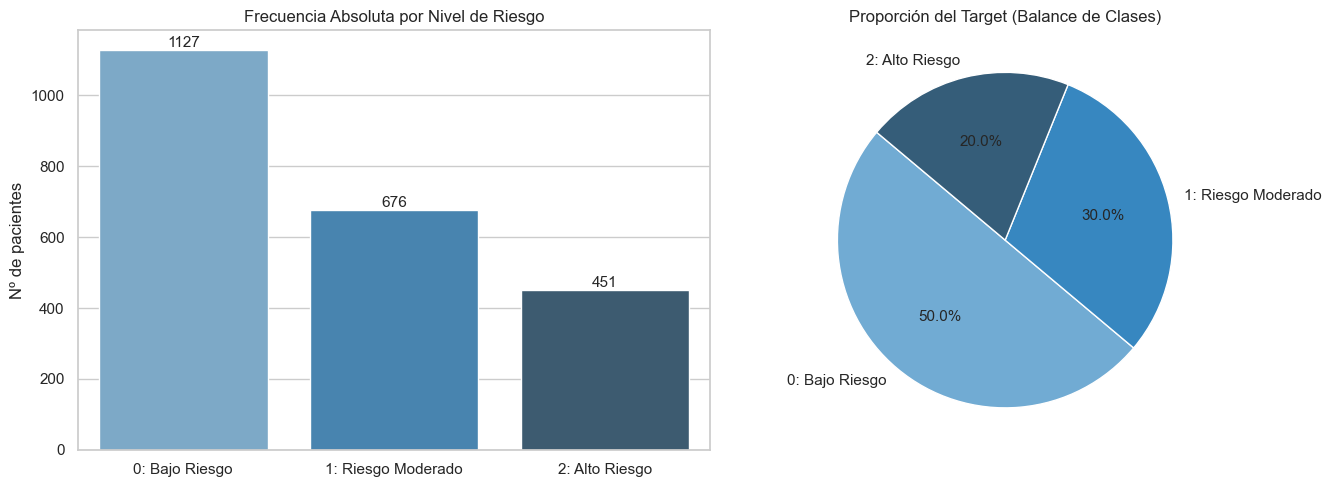

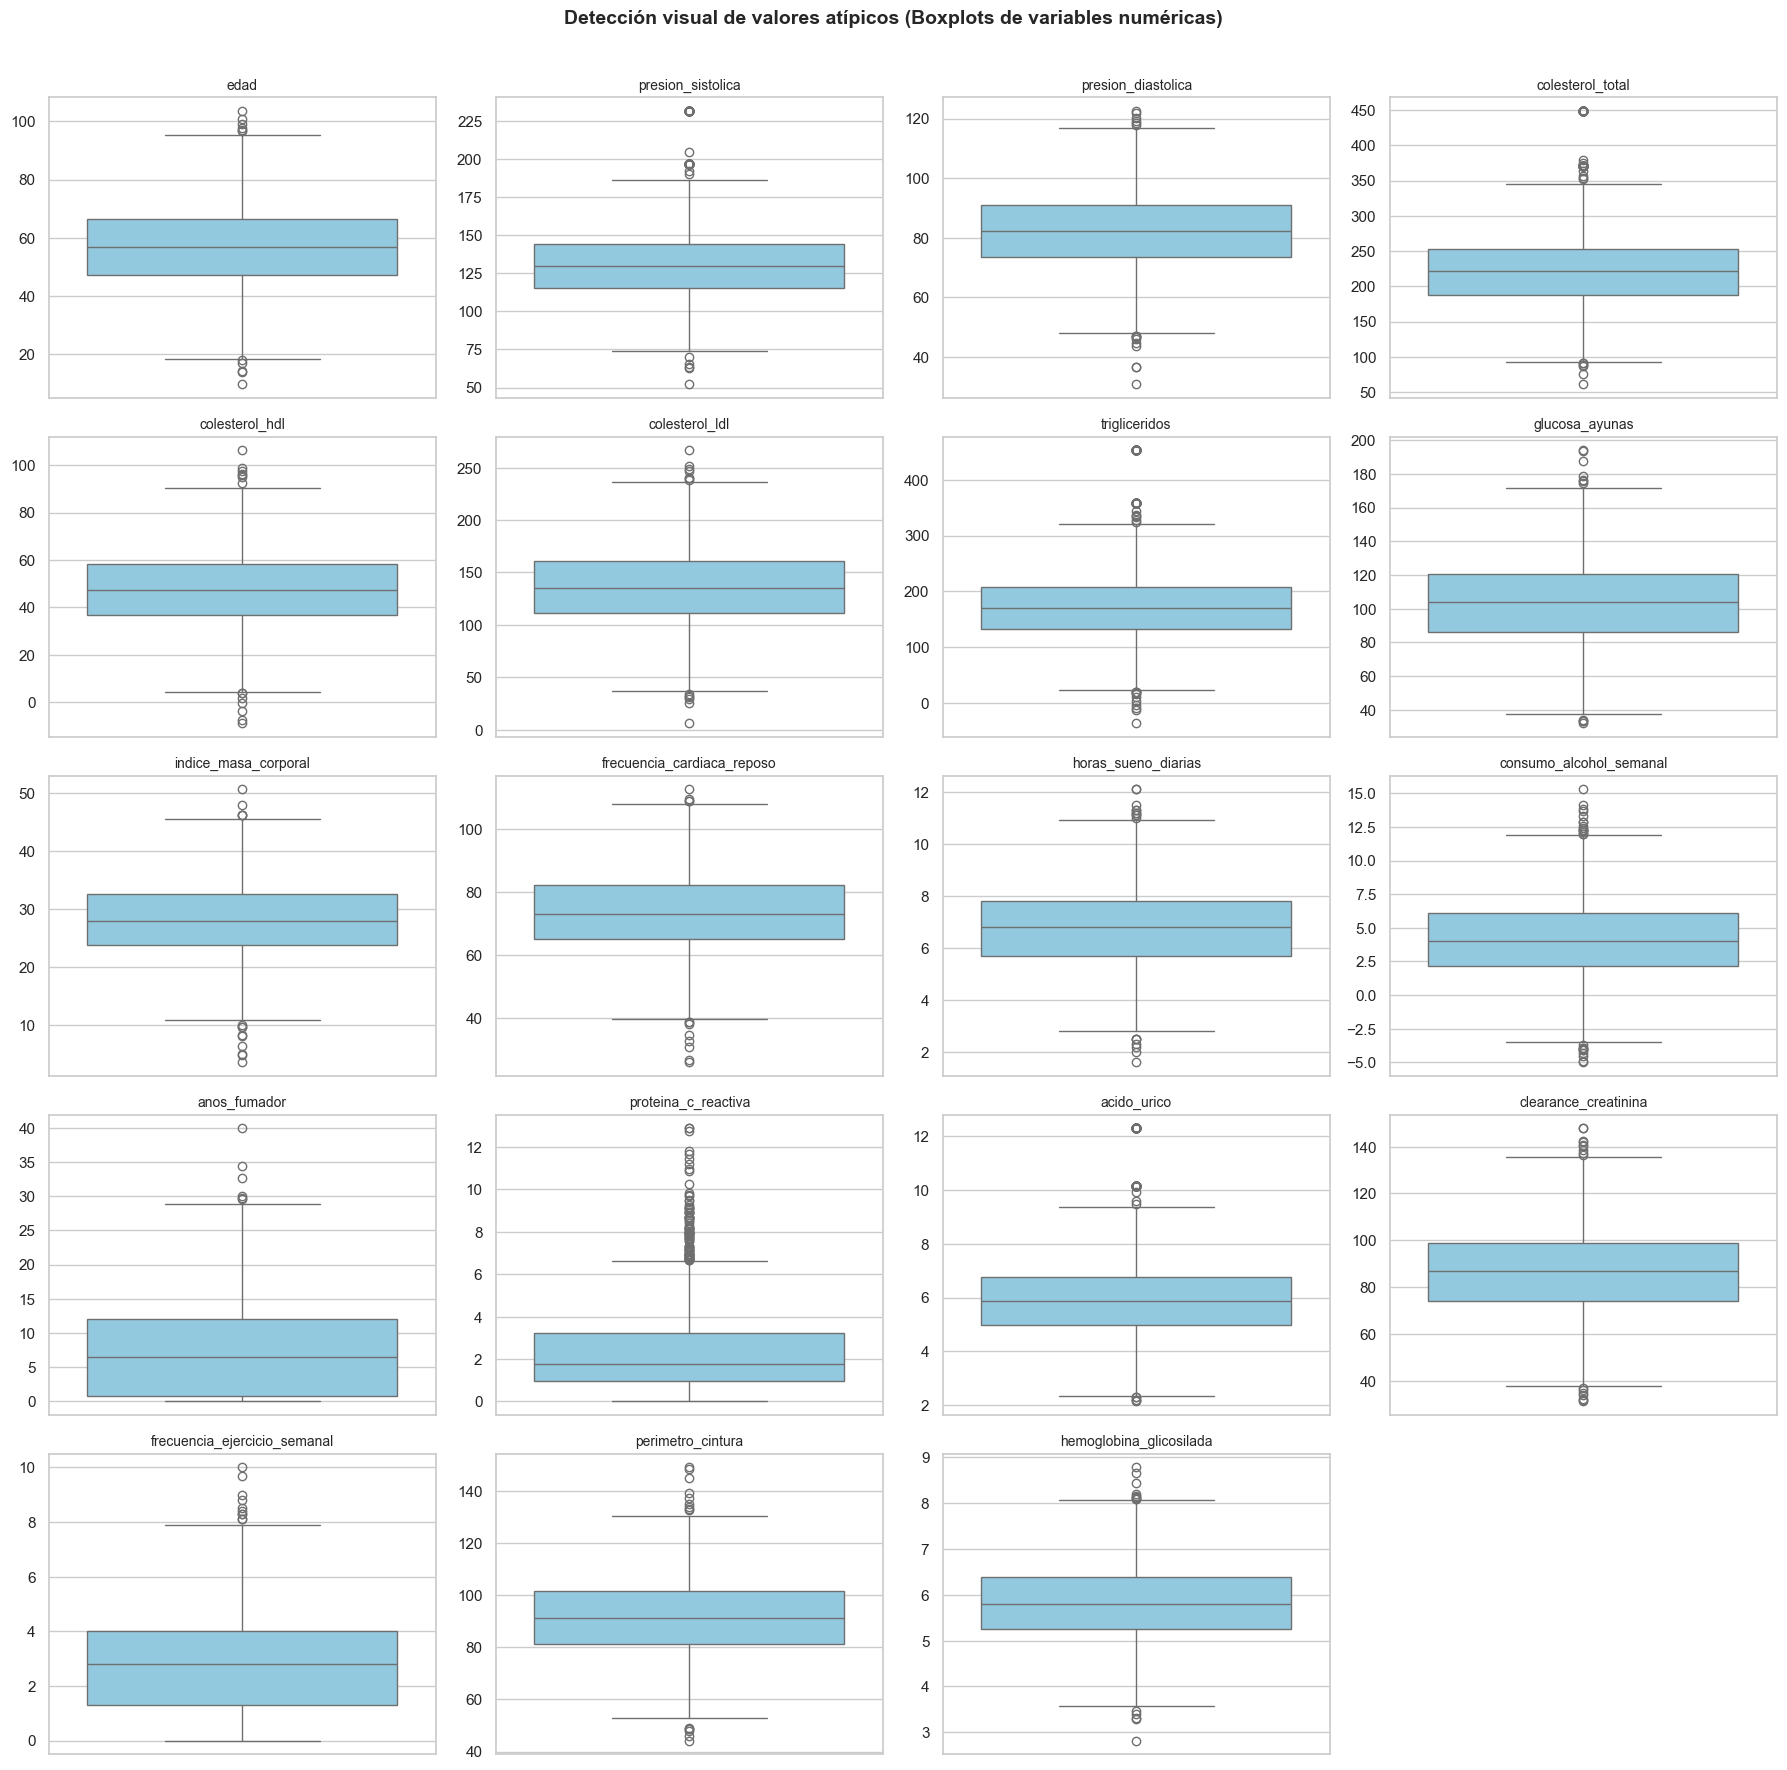

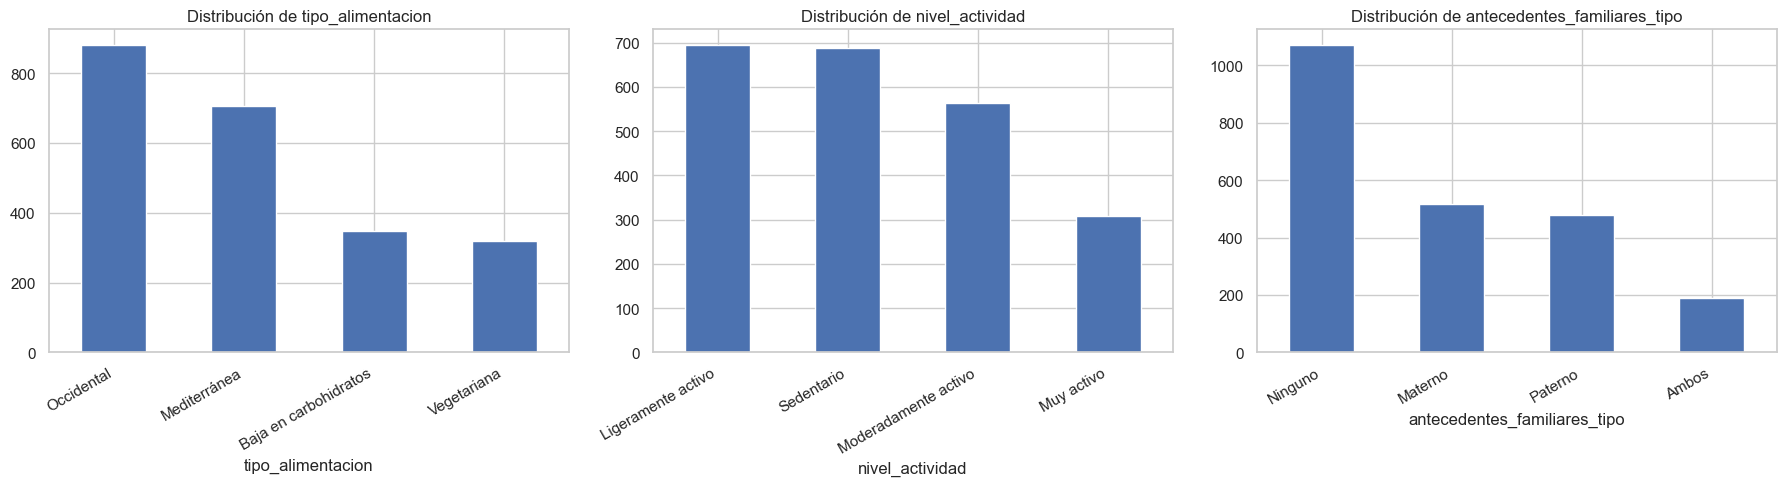

In [6]:
# 1. Distribución del target (riesgo_cardiovascular)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_counts = df[TARGET_COL].value_counts().sort_index()
class_labels = [
    "0: Bajo Riesgo",
    "1: Riesgo Moderado",
    "2: Alto Riesgo",
]

sns.barplot(
    x=class_labels,
    y=class_counts.values,
    palette="Blues_d",
    ax=axes[0],
    hue=class_labels,
    legend=False,
)
axes[0].set_title("Frecuencia Absoluta por Nivel de Riesgo")
axes[0].set_ylabel("Nº de pacientes")
for p in axes[0].patches:
    axes[0].annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 5),
        textcoords="offset points",
    )

axes[1].pie(
    class_counts,
    labels=class_labels,
    autopct="%1.1f%%",
    colors=sns.color_palette("Blues_d", 3),
    startangle=140,
)
axes[1].set_title("Proporción del Target (Balance de Clases)")
plt.tight_layout()
plt.show()

# 2. Histogramas y Boxplots de variables numéricas para detectar asimetrías y outliers
n_num = len(NUM_COLS)
cols = 4
rows = (n_num + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, rows * 3.5))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Detección visual de valores atípicos (Boxplots de variables numéricas)",
    y=1.01,
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# 3. Distribución de variables categóricas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(CAT_COLS):
    df[col].value_counts().plot(kind="bar", ax=axes[i], color="#4C72B0")
    axes[i].set_title(f"Distribución de {col}")
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()

En la variable a predecir se detecta un desbalanceo moderado, llegando a tener la clase 2 menos de la mitad de los ejemplos que la 0. Si los resultados de los modelos no son favorables, se podría estudiar la posibilidad de aplicar técnicas de balanceo.

En los atributos con valores negativos imposibles o valores fuera de su rango posible mencionados anteriormente, se puede observar que no son casos aislados, sino que hay varios valores con el mismo problema. Estos valores deberán ser corregidos aplicando alguna estrategia.

Hay varias variables que tienen varios valores atípicos, especialmente `proteina_c_reactiva`, que posee una notable dispersión de valores atípicos con asimetría positiva severa. En un principio, se consideran estas dos estrategias:
* Al estar prediciendo sobre un campo de la medicina, se justifica que se mantengan estos valores atípicos, ya que ayudarán a detectar riesgos altos.
* La dispersión de valores atípicos, al ser tan severa, justifica la necesidad imperativa de un preprocesamiento basado en corrección de cotas y escalado robusto.

Podemos ver en los tipos enumerados que serán necesarias variables dummy binarias para separar los tipos de alimentación y los tipos de antecedentes familiares, para facilitar a los futuros modelos la identificación de patrones en nuestros datos. Con respecto al nivel de actividad, lo tendremos en cuenta, si lo utilizamos, como característica ordinal con números del 0 al 3 para numerar estos niveles de actividad por el mismo motivo que estableceremos dummies para las dos anteriores características discutidas.

## Análisis bivariante / relación con la variable objetivo

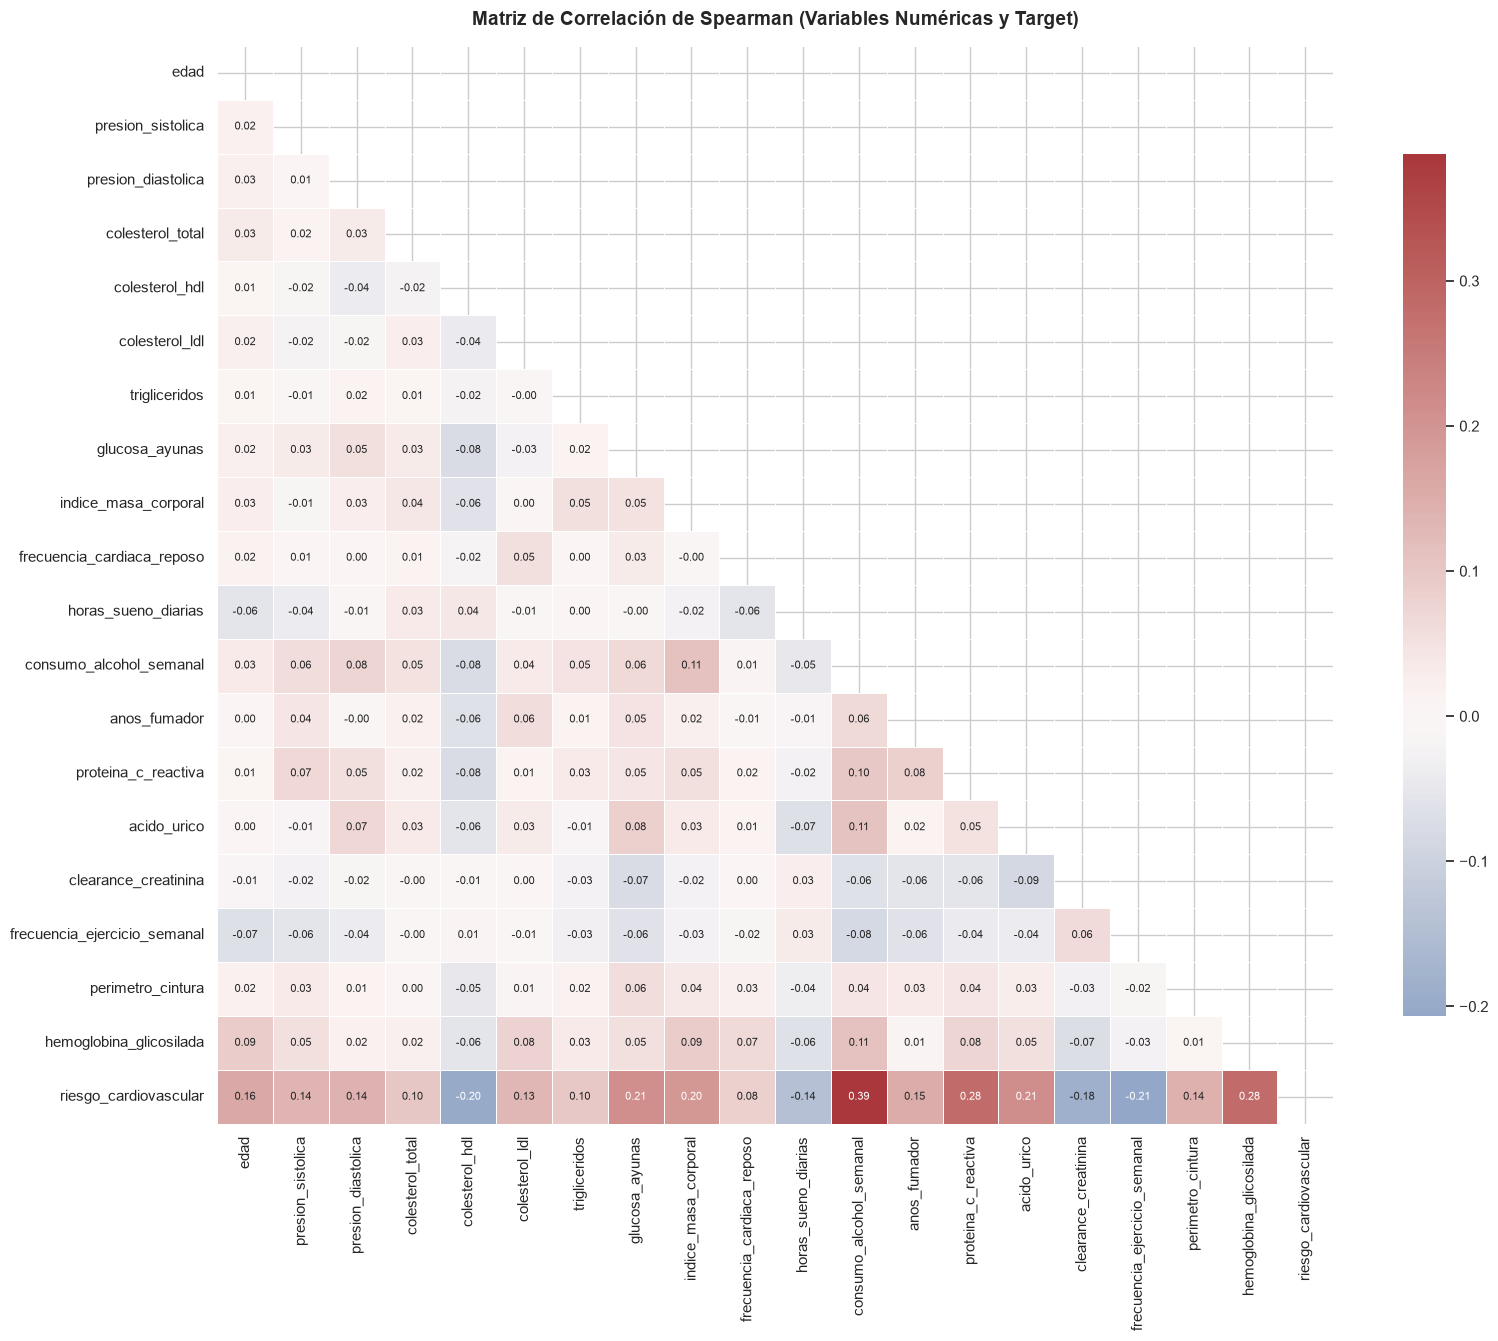

TOP 8 VARIABLES NUMÉRICAS MÁS ASOCIADAS EMPÍRICAMENTE AL RIESGO CARDIOVASCULAR
 • consumo_alcohol_semanal     : Spearman r = +0.388  (Factor de Riesgo (+))
 • hemoglobina_glicosilada     : Spearman r = +0.283  (Factor de Riesgo (+))
 • proteina_c_reactiva         : Spearman r = +0.282  (Factor de Riesgo (+))
 • acido_urico                 : Spearman r = +0.213  (Factor de Riesgo (+))
 • glucosa_ayunas              : Spearman r = +0.210  (Factor de Riesgo (+))
 • frecuencia_ejercicio_semanal: Spearman r = -0.207  (Factor Protector (-))
 • colesterol_hdl              : Spearman r = -0.200  (Factor Protector (-))
 • indice_masa_corporal        : Spearman r = +0.196  (Factor de Riesgo (+))


C:\Users\Usuario\AppData\Local\Temp\ipykernel_7624\384412969.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[idx].set_xticklabels(class_labels_short)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_7624\384412969.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[idx].set_xticklabels(class_labels_short)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_7624\384412969.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[idx].set_xticklabels(class_labels_short)
C:\Users\Usuario\AppData\Local\Temp\ipykernel_7624\384412969.py:68: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after s

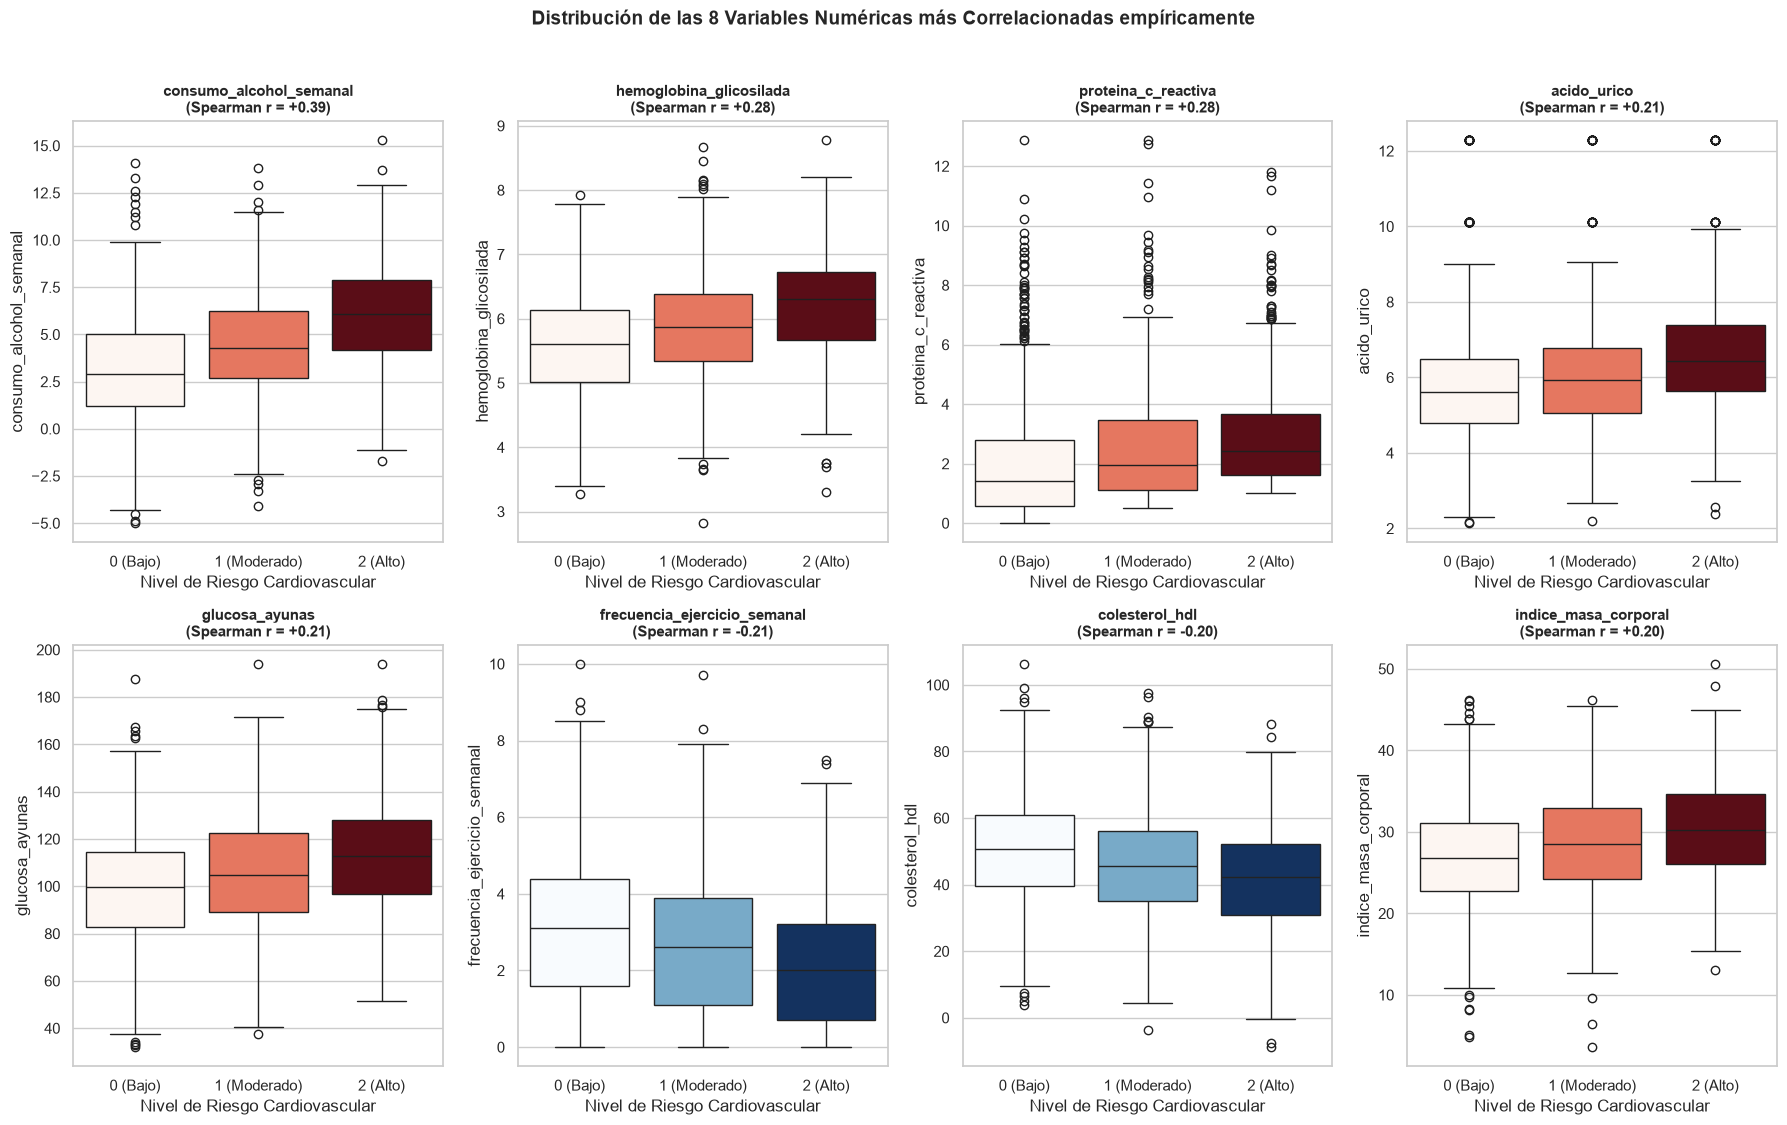

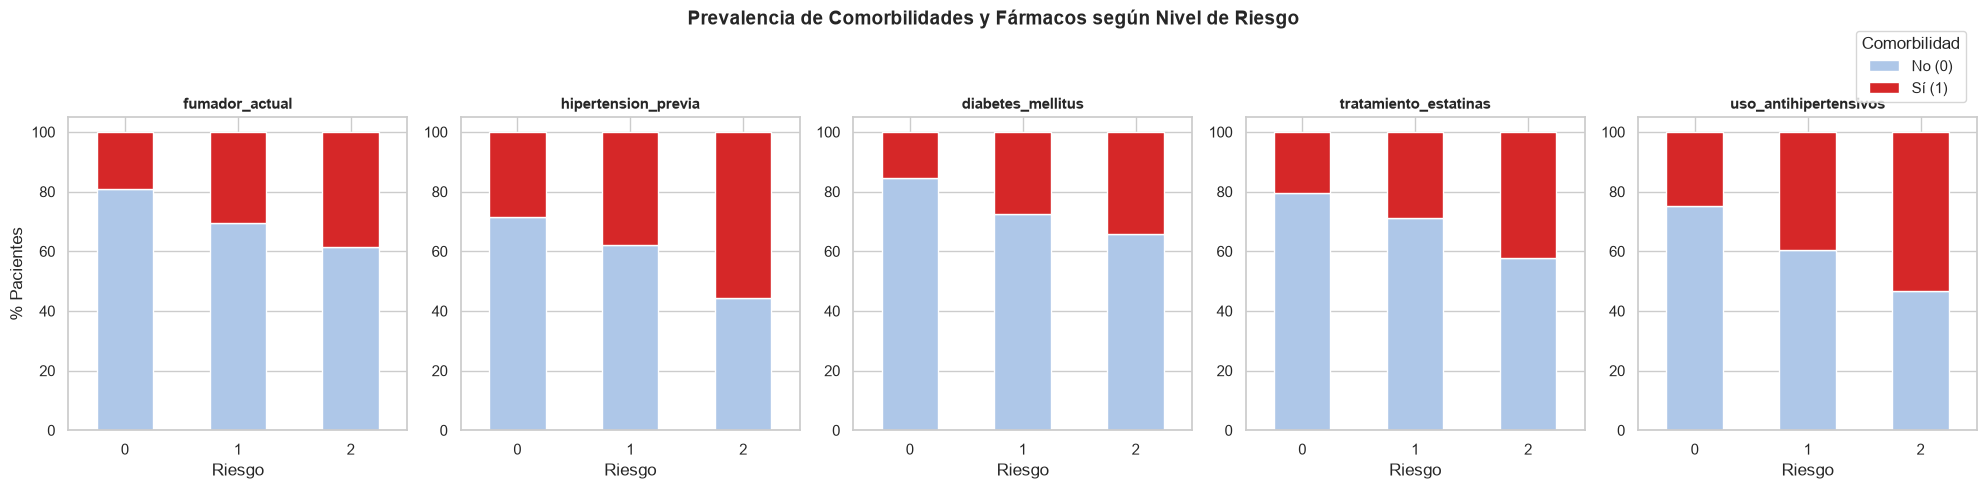

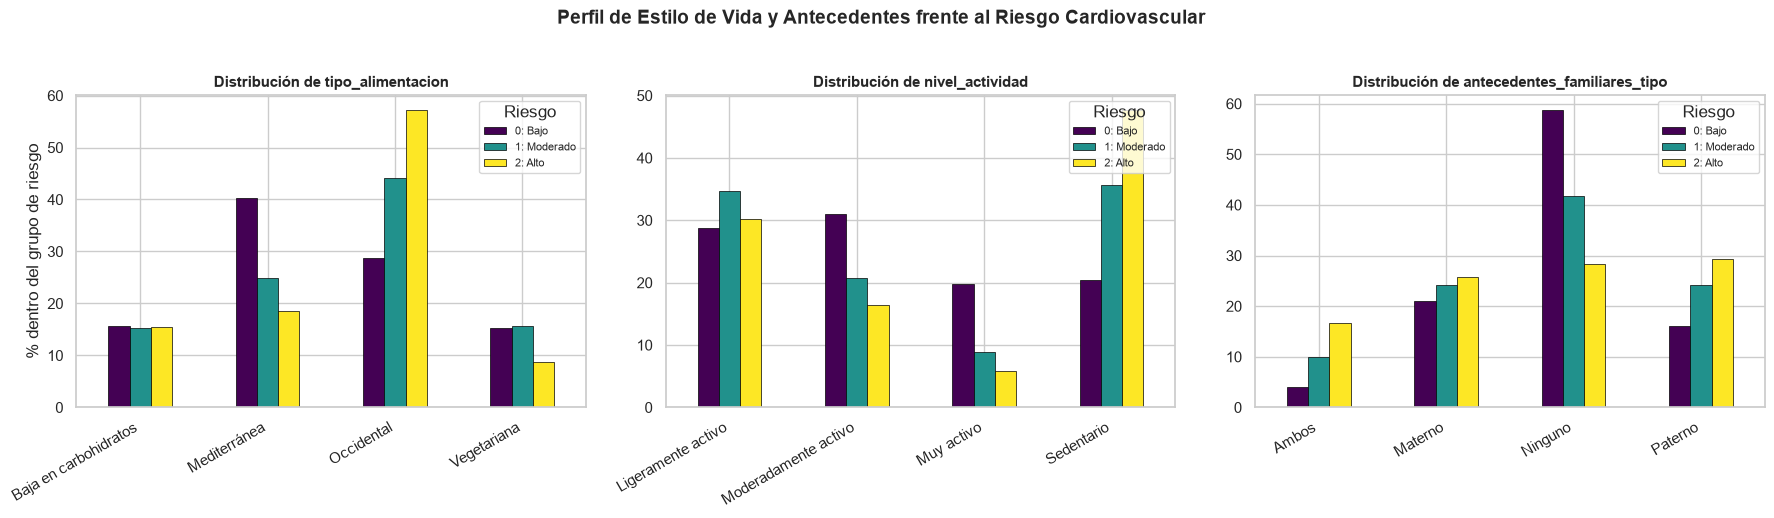

In [18]:
# ==============================================================================
# ANÁLISIS BIVARIANTE / RELACIÓN CON LA VARIABLE OBJETIVO
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. MATRIZ DE CORRELACIÓN DE SPEARMAN (NUMÉRICAS + TARGET)
# ------------------------------------------------------------------------------
plt.figure(figsize=(18, 14))
corr_matrix = df[NUM_COLS + [TARGET_COL]].corr(method="spearman")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title(
    "Matriz de Correlación de Spearman (Variables Numéricas y Target)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.show()

# ------------------------------------------------------------------------------
# 2. TOP VARIABLES NUMÉRICAS CON MAYOR PODER DISCRIMINATORIO EMPÍRICO
# ------------------------------------------------------------------------------
# Seleccionamos las 8 de mayor magnitud absoluta (positivas o protectoras/negativas)
corr_with_target = corr_matrix.loc[NUM_COLS, TARGET_COL]
top_features = corr_with_target.abs().sort_values(ascending=False).head(8).index
print("=" * 70)
print(
    "TOP 8 VARIABLES NUMÉRICAS MÁS ASOCIADAS EMPÍRICAMENTE AL RIESGO CARDIOVASCULAR"
)
print("=" * 70)
for feat in top_features:
    r_val = corr_with_target[feat]
    tipo = "Factor de Riesgo (+)" if r_val > 0 else "Factor Protector (-)"
    print(f" • {feat:28s}: Spearman r = {r_val:+.3f}  ({tipo})")

# Visualización mediante Boxplots estratificados por nivel de riesgo
fig, axes = plt.subplots(2, 4, figsize=(18, 11))
axes = axes.flatten()

class_labels_short = ["0 (Bajo)", "1 (Moderado)", "2 (Alto)"]

for idx, col in enumerate(top_features):
    r_val = corr_with_target[col]
    sns.boxplot(
        x=TARGET_COL,
        y=col,
        data=df,
        ax=axes[idx],
        palette="Reds" if r_val > 0 else "Blues",
        hue=TARGET_COL,
        legend=False,
    )
    axes[idx].set_title(
        f"{col}\n(Spearman r = {r_val:+.2f})", fontsize=11, fontweight="bold"
    )
    axes[idx].set_xlabel("Nivel de Riesgo Cardiovascular")
    axes[idx].set_xticklabels(class_labels_short)
    axes[idx].set_ylabel(col)

plt.suptitle(
    "Distribución de las 8 Variables Numéricas más Correlacionadas empíricamente",
    y=1.02,
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3. ASOCIACIÓN DE TODAS LAS COMORBILIDADES (BOOLEANAS) CON EL TARGET
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(BOOL_COLS), figsize=(20, 4.5))

for idx, col in enumerate(BOOL_COLS):
    # Proporción de presencia de la comorbilidad dentro de cada nivel de riesgo
    ct = pd.crosstab(df[TARGET_COL], df[col], normalize="index") * 100
    ct.plot(
        kind="bar",
        stacked=True,
        ax=axes[idx],
        color=["#aec7e8", "#d62728"],
        legend=False,
    )
    axes[idx].set_title(f"{col}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Riesgo")
    axes[idx].set_xticklabels(["0", "1", "2"], rotation=0)
    axes[idx].set_ylabel("% Pacientes" if idx == 0 else "")

# Leyenda unificada para el bloque booleano
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    ["No (0)", "Sí (1)"],
    loc="upper right",
    bbox_to_anchor=(0.99, 1.05),
    title="Comorbilidad",
)
plt.suptitle(
    "Prevalencia de Comorbilidades y Fármacos según Nivel de Riesgo",
    y=1.08,
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS NOMINALES / ORDINALES FRENTE AL TARGET
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(18, 5))

for idx, col in enumerate(CAT_COLS):
    # Porcentaje de cada categoría dentro de cada estrato de riesgo
    ct_cat = pd.crosstab(df[col], df[TARGET_COL], normalize="columns") * 100
    ct_cat.plot(
        kind="bar",
        ax=axes[idx],
        colormap="viridis",
        edgecolor="black",
        linewidth=0.5,
    )
    axes[idx].set_title(
        f"Distribución de {col}", fontsize=11, fontweight="bold"
    )
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel("% dentro del grupo de riesgo" if idx == 0 else "")
    axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=30, ha="right")
    axes[idx].legend(
        title="Riesgo",
        labels=["0: Bajo", "1: Moderado", "2: Alto"],
        loc="upper right",
        fontsize=8,
    )

plt.suptitle(
    "Perfil de Estilo de Vida y Antecedentes frente al Riesgo Cardiovascular",
    y=1.03,
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()
plt.show()


Análisis bivariante de variables numéricas clave: En la evaluación de las variables cuantitativas más correlacionadas, se observa un incremento escalonado en los marcadores de daño inflamatorio y metabólico (`consumo_alcohol_semanal` con $r = +0.39$, `proteina_c_reactiva` y `hemoglobina_glicosilada` ambas con $r = +0.28$, junto a `acido_urico` y `glucosa_ayunas` con $r = +0.21$ e `indice_masa_corporal` con $r = +0.196$), frente al descenso del factor protector `frecuencia_ejercicio_semanal` ($r = -0.21$) y `colesterol_hdl` ($r = -0.20$). No obstante, el solapamiento parcial de los rangos intercuartílicos entre clases contiguas constata la imposibilidad de una separación lineal univariante simple.

En cuanto a la relación entre las variables predictoras y el target, la matriz de correlación muestra que la variable más correlacionada con tener un riesgo cardiovascular alto es `consumo_alcohol_semanal` y en general poseen una correlación positiva moderada. En general, los valores de las correlaciones entre las variables predictoras y el target son bastante sólidos al situarse en valores moderados, indicando que las variables elegidas serán útiles para que los modelos puedan predecir el riesgo correctamente. Tampoco hay ninguna variable excesivamente correlacionada con el target para determinar que el problema de detectar el riesgo cardiovascular depende de una única variable. Los boxplot demuestran que las variables correlacionadas positivamente (los boxplot rojos) tienden a presentar un mayor riesgo cardiovascular a medida que se aumenta su valor, mientras que las variables correlacionadas negativamente (las azules) al aumentar su valor, menos riesgo suele haber.

En cuanto a la relación entre las variables predictoras, presentan valores de correlación cercanos a 0, lo que indica que las variables son independientes y que no hay multicolinealidad, por lo que no hay columnas redundantes a eliminar ni necesidad de aplicar PCA que aplicar de momento. Cabe destacar que las columnas `colesterol_hdl` y `colesterol_ldl`, sobre las que se planteaba la hipótesis de que podían estar relacionadas con la columna `colesterol_total` (y que ahora se sabe que se relacionan con la fórmula `colesterol_hdl` + `colesterol_ldl` + `trigliceridos` / 5) no muestran una correlación clara entre sí, lo que resulta llamativo y habrá que analizar más adelante para ver qué está ocurriendo con estas variables y si se deberán mantener intactas o no.

El patrón en las 5 variables es monótono creciente en la segunda gráfica de comorbilidades (presencia de una o más enfermedades, patológicas o crónicas adicionales): a mayor nivel de riesgo cardiovascular, mayor es la prevalencia de todas las patologías y tratamientos analizados. Las dos condiciones que muestran mayor capacidad de separación son la hipertensión previa y el uso de antihipertensivos, donde la presencia de la condición pasa de ser minoritaria en el grupo 0 a superar el 50% en el grupo 2.

En la última gráfica podemos ver un riesgo menor en los pacientes que basan su alimentación en la cultura Mediterránea, junto con la vegetariana, la cual parece que tienen el riesgo alto reducido con respecto a los otros valores. Podemos ver también más de un 50% de riesgo 2 para pacientes con alimentación Occidental.

También podemos observar una reducción de riesgo en los pacientes conforme van teniendo un nivel de actividad superior, teniendo casi al 50% de los pacientes con riesgo 2 en el grupo de sedentarios. Además alrededor del 60% de los pacientes con riesgo bajo se sitúan en el grupo que no tienen antecedentes familiares. Dentro del antecedente paterno y en ambos, podemos observar un aumento de casos de riesgo 2 con respecto al riesgo 0.

## Identificación de problemáticas

In [19]:
# ==============================================================================
# AUDITORÍA INTEGRAL DE CALIDAD DEL DATO Y PROBLEMÁTICAS (REQUISITO 3.1)
# ==============================================================================

print("=" * 75)
print("INFORME DE AUDITORÍA DE CALIDAD Y LIMITACIONES DEL DATASET")
print("=" * 75)

# ------------------------------------------------------------------------------
# 1. VALORES FÍSICAMENTE / BIOLÓGICAMENTE IMPOSIBLES (VALORES NEGATIVOS)
# ------------------------------------------------------------------------------
print("\n🚨 1. INCONSISTENCIAS DE DOMINIO: VALORES NEGATIVOS IMPOSIBLES")
print("-" * 75)

non_negative_vars = [
    "edad",
    "presion_sistolica",
    "presion_diastolica",
    "colesterol_total",
    "colesterol_hdl",
    "colesterol_ldl",
    "trigliceridos",
    "glucosa_ayunas",
    "indice_masa_corporal",
    "frecuencia_cardiaca_reposo",
    "horas_sueno_diarias",
    "consumo_alcohol_semanal",
    "anos_fumador",
    "proteina_c_reactiva",
    "acido_urico",
    "clearance_creatinina",
    "frecuencia_ejercicio_semanal",
    "perimetro_cintura",
    "hemoglobina_glicosilada",
]

neg_dict = {}
for col in non_negative_vars:
    if col in df.columns:
        n_neg = (df[col] < 0).sum()
        if n_neg > 0:
            neg_dict[col] = {
                "Valor Mínimo": df[col].min(),
                "Registros Negativos": n_neg,
                "% del Total": round((n_neg / len(df)) * 100, 2),
            }

if neg_dict:
    df_negativos = pd.DataFrame(neg_dict).T
    print(df_negativos)
    print(
        "⚠️ Diagnóstico: Errores de registro/adquisición en magnitudes biológicas que no admiten valores < 0."
    )
else:
    print("✓ No se detectaron valores negativos en magnitudes biológicas.")


# ------------------------------------------------------------------------------
# 2. INCOHERENCIAS FISIOLÓGICAS Y RELACIONES CLÍNICAS CRUZADAS
# ------------------------------------------------------------------------------
print("\n🩺 2. AUDITORÍA DE COHERENCIA CLÍNICA ENTRE VARIABLES")
print("-" * 75)

incoherencias_clinicas = {}

# A. Presión diastólica >= sistólica (fisiológicamente imposible)
inval_presion = (df["presion_diastolica"] >= df["presion_sistolica"]).sum()
incoherencias_clinicas["Presión Diastólica >= Sistólica"] = inval_presion

# B. Días de ejercicio semanal > 7 o negativos
inval_ejercicio = (
    (df["frecuencia_ejercicio_semanal"] > 7)
    | (df["frecuencia_ejercicio_semanal"] < 0)
).sum()
incoherencias_clinicas["Días de ejercicio fuera de rango [0, 7]"] = (
    inval_ejercicio
)

# C. Horas de sueño al día > 24 o <= 0
inval_sueno = (
    (df["horas_sueno_diarias"] > 24) | (df["horas_sueno_diarias"] <= 0)
).sum()
incoherencias_clinicas["Horas de sueño fuera de rango (0, 24]"] = inval_sueno

# D. Años fumando superiores a la edad del paciente
inval_tabaco_edad = (df["anos_fumador"] > df["edad"]).sum()
incoherencias_clinicas["Años fumando mayores que la edad"] = inval_tabaco_edad

# E. Incoherencia de lípidos: Colesterol total menor que la suma de sus fracciones (HDL + LDL)
inval_lipidos = (
    df["colesterol_total"] < (df["colesterol_hdl"] + df["colesterol_ldl"])
).sum()
incoherencias_clinicas["Colesterol Total < (HDL + LDL)"] = inval_lipidos

# F. Glucosa o HbA1c en rangos imposibles
inval_gluc = (df["glucosa_ayunas"] < 20).sum()
incoherencias_clinicas["Hipoglucemia extrema/incompatible (<20 mg/dL)"] = (
    inval_gluc
)

for prueba, count in incoherencias_clinicas.items():
    pct = round((count / len(df)) * 100, 2)
    icono = "❌" if count > 0 else "✓"
    print(f"{icono} {prueba}: {count} casos ({pct}%)")


# ------------------------------------------------------------------------------
# 3. OUTLIERS ESTADÍSTICOS (MÉTODO IQR) Y ASIMETRÍA (SKEWNESS)
# ------------------------------------------------------------------------------
print("\n📊 3. ANÁLISIS DE OUTLIERS (IQR 1.5x) Y ASIMETRÍA DE DISTRIBUCIÓN")
print("-" * 75)

outlier_skew_list = []
for col in NUM_COLS:
    q25, q75 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q75 - q25
    lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    n_outliers = (
        ((df[col] < lower) | (df[col] > upper)).sum() if iqr > 0 else 0
    )
    pct_outliers = round((n_outliers / len(df)) * 100, 2)
    skew = round(df[col].skew(), 2)

    if n_outliers > 0 or abs(skew) > 0.8:
        outlier_skew_list.append(
            {
                "Variable": col,
                "Nº Outliers": n_outliers,
                "% Outliers": pct_outliers,
                "Skewness": skew,
                "Tipo Asimetría": (
                    "Positiva (Cola dcha)"
                    if skew > 0.5
                    else (
                        "Negativa (Cola izq)"
                        if skew < -0.5
                        else "Simétrica (~Normal)"
                    )
                ),
            }
        )

df_outliers_skew = pd.DataFrame(outlier_skew_list).sort_values(
    by="% Outliers", ascending=False
)
print(df_outliers_skew.to_string(index=False))


# ------------------------------------------------------------------------------
# 4. DESBALANCEO DE CLASES Y ANÁLISIS DE COSTE CLÍNICO
# ------------------------------------------------------------------------------
print("\n⚖️ 4. ESTRATIFICACIÓN DEL TARGET Y MATRIZ DE RIESGO CLÍNICO")
print("-" * 75)

target_counts = df[TARGET_COL].value_counts().sort_index()
target_pct = (df[TARGET_COL].value_counts(normalize=True) * 100).sort_index()
class_labels = {0: "Bajo Riesgo", 1: "Riesgo Moderado", 2: "Alto Riesgo"}

for cls_idx in target_counts.index:
    print(
        f"  * Clase {cls_idx} ({class_labels[cls_idx]}): {target_counts[cls_idx]} registros ({target_pct[cls_idx]:.2f}%)"
    )

imbalance_ratio = round(target_counts.max() / target_counts.min(), 2)
print(f"\nRatio de desbalanceo (Clase 0 / Clase 2): {imbalance_ratio}:1")
print(
    "⚠️ Impacto Clínico: La Clase 2 (Alto Riesgo) es minoritaria (20.01%)."
)
print(
    "   Un Falso Negativo (predecir Clase 0 en un paciente de Clase 2) acarrea riesgo vital."
)


# ------------------------------------------------------------------------------
# 5. ATRIBUTOS CATEGÓRICOS QUE REQUIEREN TRANSFORMACIÓN
# ------------------------------------------------------------------------------
print("\n🔤 5. VARIABLES CATEGÓRICAS Y ESTRATEGIA DE CODIFICACIÓN NECESARIA")
print("-" * 75)
for col in CAT_COLS:
    modalidades = df[col].unique().tolist()
    print(f"  * {col} ({len(modalidades)} categorías): {modalidades}")

INFORME DE AUDITORÍA DE CALIDAD Y LIMITACIONES DEL DATASET

🚨 1. INCONSISTENCIAS DE DOMINIO: VALORES NEGATIVOS IMPOSIBLES
---------------------------------------------------------------------------
                         Valor Mínimo  Registros Negativos  % del Total
colesterol_hdl                   -8.8                  4.0         0.18
trigliceridos                   -35.7                  4.0         0.18
consumo_alcohol_semanal          -5.0                177.0         7.85
⚠️ Diagnóstico: Errores de registro/adquisición en magnitudes biológicas que no admiten valores < 0.

🩺 2. AUDITORÍA DE COHERENCIA CLÍNICA ENTRE VARIABLES
---------------------------------------------------------------------------
❌ Presión Diastólica >= Sistólica: 44 casos (1.95%)
❌ Días de ejercicio fuera de rango [0, 7]: 41 casos (1.82%)
✓ Horas de sueño fuera de rango (0, 24]: 0 casos (0.0%)
❌ Años fumando mayores que la edad: 1 casos (0.04%)
❌ Colesterol Total < (HDL + LDL): 559 casos (24.8%)
✓ Hipogluce

In [20]:
# ==============================================================================
# AUDITORÍA AVANZADA: OTRAS INCONSISTENCIAS Y DISCORDANCIAS CLÍNICAS OCULTAS
# ==============================================================================
print("=" * 75)
print("AUDITORÍA DE INCONSISTENCIAS AVANZADAS Y DISCORDANCIAS CRUZADAS")
print("=" * 75)

# A. Población adulta (el enunciado especifica 'Población Adulta')
menores_edad = (df["edad"] < 18).sum()
print(
    f"1. Pacientes pediátricos (< 18 años): {menores_edad} casos (Min edad: {df['edad'].min()})"
)

# B. Discordancia: Fumador pasivo/no fumador con años de fumador
fuma_incongruente = (
    (df["fumador_actual"] == 0) & (df["anos_fumador"] > 0)
).sum()
no_fuma_anos = ((df["fumador_actual"] == 1) & (df["anos_fumador"] == 0)).sum()
print(
    f"2. 'No fumador actual' con años acumulados (¿exfumador?): {fuma_incongruente} casos"
)
print(f"3. 'Fumador actual' con 0 años fumando: {no_fuma_anos} casos")

# C. Discordancia de estilo de vida: Nivel de actividad vs Días de ejercicio
sedentario_mucho_ejercicio = (
    (df["nivel_actividad"] == "Sedentario")
    & (df["frecuencia_ejercicio_semanal"] >= 4)
).sum()
activo_sin_ejercicio = (
    (df["nivel_actividad"] == "Muy activo")
    & (df["frecuencia_ejercicio_semanal"] == 0)
).sum()
print(
    f"4. Declara 'Sedentario' pero hace >= 4 días de ejercicio/semana: {sedentario_mucho_ejercicio} casos"
)
print(
    f"5. Declara 'Muy activo' pero hace 0 días de ejercicio/semana: {activo_sin_ejercicio} casos"
)

# D. Discordancia de comorbilidad vs fármaco:
# ¿Toma antihipertensivos sin diagnóstico de hipertensión?
farmaco_sin_diag_hta = (
    (df["uso_antihipertensivos"] == 1) & (df["hipertension_previa"] == 0)
).sum()
print(
    f"6. Uso de antihipertensivos sin diagnóstico previo de HTA: {farmaco_sin_diag_hta} casos"
)

# ¿Toma estatinas sin colesterol elevado ni diagnóstico?
estatinas_ldl_bajo = (
    (df["tratamiento_estatinas"] == 1) & (df["colesterol_ldl"] < 70)
).sum()
print(
    f"7. Estatinas con LDL < 70 mg/dL (posible buen control terapéutico): {estatinas_ldl_bajo} casos"
)

# E. Diabetes no diagnosticada (HbA1c >= 6.5% o Glucosa >= 126 mg/dL sin DM previa)
diabetico_oculto = (
    (df["diabetes_mellitus"] == 0)
    & ((df["hemoglobina_glicosilada"] >= 6.5) | (df["glucosa_ayunas"] >= 126))
).sum()
print(
    f"8. Criterio de diabetes analítica no diagnosticada previamente: {diabetico_oculto} casos"
)

# F. Discrepancia lipídica (Fórmula de Friedewald: Colesterol Total ~= HDL + LDL + TG/5)
# Si Colesterol Total difiere más de un 50% de la estimación teórica:
colesterol_estimado = (
    df["colesterol_hdl"] + df["colesterol_ldl"] + (df["trigliceridos"] / 5.0)
)
desfase_lipidos = (
    np.abs(df["colesterol_total"] - colesterol_estimado)
    / df["colesterol_total"]
    > 0.50
).sum()
print(
    f"9. Discordancia severa (>50% error) con fórmula lipídica de Friedewald: {desfase_lipidos} casos"
)

# G. Frecuencias cardíacas o presiones en parada/incompatibles
fc_extrema = (
    (df["frecuencia_cardiaca_reposo"] < 35)
    | (df["frecuencia_cardiaca_reposo"] > 180)
).sum()
print(
    f"10. Frecuencia cardíaca en reposo incompatible/extrema (<35 o >180 lpm): {fc_extrema} casos"
)

AUDITORÍA DE INCONSISTENCIAS AVANZADAS Y DISCORDANCIAS CRUZADAS
1. Pacientes pediátricos (< 18 años): 4 casos (Min edad: 9.8)
2. 'No fumador actual' con años acumulados (¿exfumador?): 1279 casos
3. 'Fumador actual' con 0 años fumando: 123 casos
4. Declara 'Sedentario' pero hace >= 4 días de ejercicio/semana: 173 casos
5. Declara 'Muy activo' pero hace 0 días de ejercicio/semana: 28 casos
6. Uso de antihipertensivos sin diagnóstico previo de HTA: 478 casos
7. Estatinas con LDL < 70 mg/dL (posible buen control terapéutico): 23 casos
8. Criterio de diabetes analítica no diagnosticada previamente: 597 casos
9. Discordancia severa (>50% error) con fórmula lipídica de Friedewald: 212 casos
10. Frecuencia cardíaca en reposo incompatible/extrema (<35 o >180 lpm): 5 casos


In [21]:
# ==============================================================================
# AUDITORÍA EXHAUSTIVA DE INTEGRIDAD DE DATOS (TESTS ADICIONALES)
# ==============================================================================
print("=" * 80)
print("AUDITORÍA FORENSE AVANZADA DEL DATASET")
print("=" * 80)

# 1. COMPROBACIÓN DE DECIMALES EN VARIABLES DISCRETAS / ENTERAS
vars_deberian_ser_enteras = [
    "edad",
    "frecuencia_ejercicio_semanal",
    "anos_fumador",
    "frecuencia_cardiaca_reposo",
    "consumo_alcohol_semanal",
]
print("\n🔍 1. Comprobación de tipos discretos con valores flotantes/decimales:")
for col in vars_deberian_ser_enteras:
    con_decimales = (df[col] % 1 != 0).sum()
    print(
        f"  * {col}: {con_decimales} registros con parte decimal (ej. {df[col].dropna().iloc[0]})"
    )

# 2. INCONGRUENCIAS TEMPORALES DEL TABAQUISMO (Fumar en la infancia)
# Pacientes que habrían empezado a fumar antes de los 12 años
edad_inicio_tabaco = df["edad"] - df["anos_fumador"]
fuma_infancia = (
    (df["anos_fumador"] > 0) & (edad_inicio_tabaco < 12) & (df["edad"] >= 18)
).sum()
print(
    f"\n🔍 2. Inicio de tabaquismo antes de los 12 años: {fuma_infancia} pacientes adultos"
)

# 3. CONSUMO DE ALCOHOL Y TABACO EN MENORES DE EDAD
menores_alcohol = ((df["edad"] < 18) & (df["consumo_alcohol_semanal"] > 0)).sum()
menores_tabaco = (
    (df["edad"] < 18)
    & ((df["fumador_actual"] == 1) | (df["anos_fumador"] > 0))
).sum()
print(
    f"🔍 3. Pacientes < 18 años con consumo de alcohol: {menores_alcohol} | con tabaco: {menores_tabaco}"
)

# 4. DISCORDANCIA ANTROPOMÉTRICA (IMC vs Perímetro de Cintura)
# Obesidad grado II/III (IMC > 35) con cintura de persona delgada (< 75 cm) o viceversa
incoherencia_antropo = (
    ((df["indice_masa_corporal"] > 35) & (df["perimetro_cintura"] < 75))
    | ((df["indice_masa_corporal"] < 18.5) & (df["perimetro_cintura"] > 110))
).sum()
print(
    f"🔍 4. Inconsistencia severa entre IMC y Perímetro de cintura: {incoherencia_antropo} casos"
)

# 5. DISCORDANCIA GLUCOSA vs HEMOGLOBINA GLICOSILADA
# HbA1c normal (<5.5%) con Glucosa diabética severa (>180 mg/dL) o viceversa
incoherencia_glucemica = (
    ((df["hemoglobina_glicosilada"] < 5.5) & (df["glucosa_ayunas"] > 180))
    | ((df["hemoglobina_glicosilada"] > 9.0) & (df["glucosa_ayunas"] < 80))
).sum()
print(
    f"🔍 5. Incoherencia metabólica cruzada (Glucosa vs HbA1c): {incoherencia_glucemica} casos"
)

# 6. LIMPIEZA DE CADENAS DE TEXTO (Espacios en blanco ocultos / Typos)
print("\n🔍 6. Integridad de categorías textuales (espacios y capitalización):")
for col in CAT_COLS:
    valores_unicos = df[col].tolist()
    valores_limpios = [str(x).strip() for x in valores_unicos]
    espacios_ocultos = sum(1 for a, b in zip(valores_unicos, valores_limpios) if a != b)
    print(
        f"  * {col}: {espacios_ocultos} valores con espacios iniciales/finales indeseados"
    )

# 7. VALORES EN VARIABLES BOOLEANAS
print("\n🔍 7. Integridad de variables binarias / booleanas:")
for col in BOOL_COLS:
    valores_set = set(df[col].dropna().unique())
    print(f"  * {col}: Valores presentes -> {valores_set}")

# 8. PRESIÓN DE PULSO TRAS CORREGIR LA INVERSIÓN SISTÓLICA/DIASTÓLICA
# Calculamos la presión de pulso asumiendo que los 44 casos invertidos se corrigen
pas_corregida = df[["presion_sistolica", "presion_diastolica"]].max(axis=1)
pad_corregida = df[["presion_sistolica", "presion_diastolica"]].min(axis=1)
presion_pulso = pas_corregida - pad_corregida

pp_inverosimil = (
    presion_pulso < 15
).sum()  # Menos de 15 mmHg es shock cardiogénico o taponamiento
print(
    f"\n🔍 8. Presión de pulso inverosímil (<15 mmHg) tras corregir inversión: {pp_inverosimil} casos (Mín PP: {presion_pulso.min():.1f} mmHg)"
)

AUDITORÍA FORENSE AVANZADA DEL DATASET

🔍 1. Comprobación de tipos discretos con valores flotantes/decimales:
  * edad: 2046 registros con parte decimal (ej. 57.4)
  * frecuencia_ejercicio_semanal: 1836 registros con parte decimal (ej. 3.3)
  * anos_fumador: 1588 registros con parte decimal (ej. 9.4)
  * frecuencia_cardiaca_reposo: 2014 registros con parte decimal (ej. 95.1)
  * consumo_alcohol_semanal: 2055 registros con parte decimal (ej. 7.6)

🔍 2. Inicio de tabaquismo antes de los 12 años: 21 pacientes adultos
🔍 3. Pacientes < 18 años con consumo de alcohol: 4 | con tabaco: 4
🔍 4. Inconsistencia severa entre IMC y Perímetro de cintura: 57 casos
🔍 5. Incoherencia metabólica cruzada (Glucosa vs HbA1c): 1 casos

🔍 6. Integridad de categorías textuales (espacios y capitalización):
  * tipo_alimentacion: 0 valores con espacios iniciales/finales indeseados
  * nivel_actividad: 0 valores con espacios iniciales/finales indeseados
  * antecedentes_familiares_tipo: 0 valores con espacios ini

In [22]:
# Comprobar el rango y los grupos de edad del dataset
print(f"Edad mínima: {df['edad'].min():.1f} años")
print(f"Edad máxima: {df['edad'].max():.1f} años")
print(f"Edad mediana: {df['edad'].median():.1f} años")

# Crear grupos etarios clínicos
bins = [0, 18, 40, 65, 120]
labels = [
    "Pediátrico (<18)",
    "Adulto Joven (18-39)",
    "Adulto Medio (40-64)",
    "Adulto Mayor (>=65)",
]
df["grupo_etario"] = pd.cut(df["edad"], bins=bins, labels=labels, right=False)

# Ver distribución por grupo y su relación con el riesgo cardiovascular
pd.crosstab(
    df["grupo_etario"],
    df["riesgo_cardiovascular"],
    normalize="index",
    margins=True,
).round(3) * 100

Edad mínima: 9.8 años
Edad máxima: 103.5 años
Edad mediana: 56.9 años


riesgo_cardiovascular,0,1,2
grupo_etario,,,
Pediátrico (<18),75.0,25.0,0.0
Adulto Joven (18-39),64.5,24.6,10.9
Adulto Medio (40-64),51.0,29.5,19.5
Adulto Mayor (>=65),41.5,33.4,25.0
All,50.0,30.0,20.0
